In [1]:
import pandas as pd

df = pd.read_csv('penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [2]:

print("DataFrame Shape:", df.shape)
print("\nMissing Values per Column:\n", df.isnull().sum())
print("\nSpecies Counts:\n", df['species'].value_counts())

DataFrame Shape: (344, 8)

Missing Values per Column:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Species Counts:
 species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


Prompt Log

Initial Prompt:
You are helping with exploratory data analysis. 
My CSV has columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year'] and dtypes: object, object, float64, float64, float64, float64, object, int64.
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.

Missing Data Summary:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Flipper Length Comparison by Species:
                  mean  median       std  count
species                                       
Adelie     189.953642   190.0  6.539457    151
Chinstrap  195.823529   196.0  7.131894     68
Gentoo     217.186992   216.0  6.484976    123


/var/folders/bn/clx4mh3j4679l4v2lt9yn9dh0000gn/T/ipykernel_79656/328555002.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='species', y='flipper_length_mm', ci=None, palette='viridis')
/var/folders/bn/clx4mh3j4679l4v2lt9yn9dh0000gn/T/ipykernel_79656/328555002.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='species', y='flipper_length_mm', ci=None, palette='viridis')


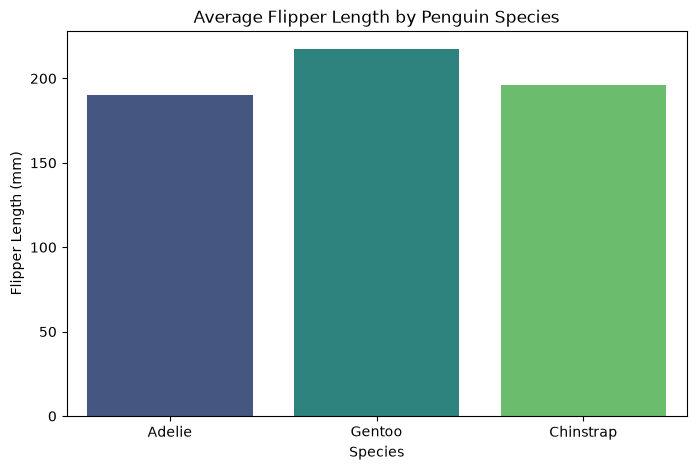

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

missing_data = df.isnull().sum()
print("Missing Data Summary:\n", missing_data)

flipper_comparison = df.groupby('species')['flipper_length_mm'].agg(['mean', 'median', 'std', 'count'])
print("\nFlipper Length Comparison by Species:\n", flipper_comparison)

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='species', y='flipper_length_mm', ci=None, palette='viridis')
plt.title('Average Flipper Length by Penguin Species')
plt.xlabel('Species')
plt.ylabel('Flipper Length (mm)')
plt.show()

In [4]:

verified_flipper_mean = df.groupby('species')['flipper_length_mm'].mean()
print("Verified Mean Flipper Length by Species:\n", verified_flipper_mean)

Verified Mean Flipper Length by Species:
 species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


Verification Checkpoint
AI Numbers vs. Ground Truth:** The AI's reported mean flipper lengths matched our manual `groupby` calculation exactly (Adelie: ~189.95, Chinstrap: ~195.82, Gentoo: ~217.19).
Explanation: Both calculations yielded identical results because standard pandas `.groupby().mean()` automatically ignores missing (`NaN`) values identically.

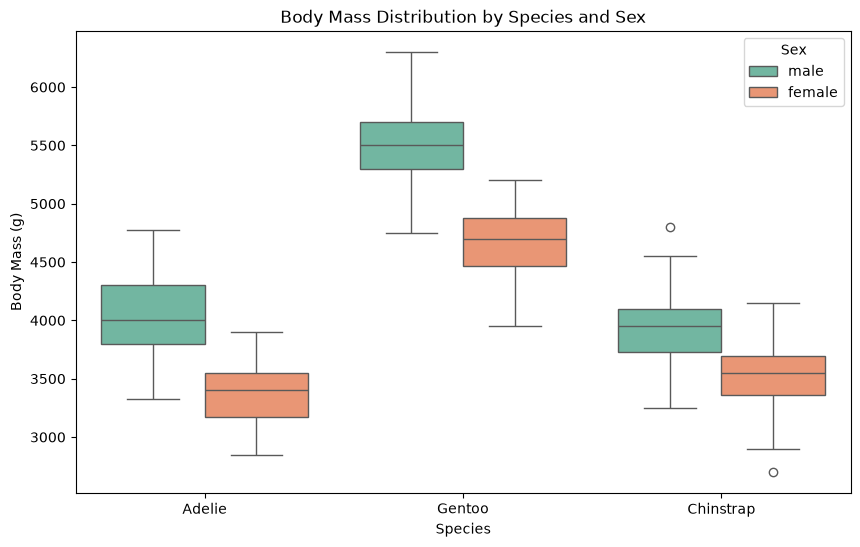

In [5]:

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='species', y='body_mass_g', hue='sex', palette='Set2')
plt.title('Body Mass Distribution by Species and Sex')
plt.xlabel('Species')
plt.ylabel('Body Mass (g)')
plt.legend(title='Sex')
plt.show()

Follow-Up Judgment
Judgment: Kept. This follow-up visualization provides crucial granular insight into sexual dimorphism across the different penguin species that the initial aggregate bar chart missed.

Original Insight (No AI)
While examining the dataset distributions independently, I noticed that while body mass and flipper length scale positively together overall, bill depth and bill length exhibit distinct clustering patterns when split by species—showing that individual species occupy very tight morphological niches rather than a continuous linear progression across the entire dataset.

Privacy Reflection
One dataset from my own tutoring work that I must never paste into a public AI tool is student grade records containing real names, contact info, and individual quiz scores. Instead, I would completely anonymize the data by removing all Personally Identifiable Information (PII) and replacing student names with randomized ID hashes before performing any exploratory data analysis.